# Revisión de la V17: verificación por cota física

Este notebook sirve para **revisar y reproducir** la V17 sin leer todo el código. Usa el código de
`MSAPSO Claude/Modelo Final/Frente_B_cola_V17/codigo/` y los resultados guardados en `resultados_V17/`.

| Sección | Qué comprueba | Tiempo |
|---|---|---|
| 1 | El código de la V17 reproduce exactamente a la V14 cuando la verificación está apagada | segundos |
| 2 | La idea en una curva concreta: por qué la V14 se equivoca de pico y cómo lo detecta la cota | segundos |
| 3 | La cola estática (p99) de la V7, la V14 y la V17, recalculada aquí | segundos |
| 4 | La energía dinámica (resultados guardados; se puede recalcular) | 1–2 min si se recalcula |
| 5 | Con ruido de medición, la debilidad que queda | lectura de resultados |
| 6 | Lista de puntos para revisar | — |

**Glosario rápido.** *pp* = puntos porcentuales (diferencia entre dos porcentajes de la potencia máxima).
*p99* = el valor que deja por debajo al 99 % de las curvas: el 1 % peor pierde eso o más.
*Estático* = una sombra fija y una sola búsqueda. *Dinámico* = la sombra cambia y se mide la energía total entregada.

**Requisitos:** `numpy scipy numba scikit-learn matplotlib pandas`.

In [1]:
import os, sys, json, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ruta al código de la V17 (relativa a la carpeta Notebooks/)
CODIGO = (Path.cwd().parent / "MSAPSO Claude" / "Modelo Final" / "Frente_B_cola_V17" / "codigo").resolve()
assert CODIGO.exists(), f"No encuentro {CODIGO}; abre el notebook desde la carpeta Notebooks/"
sys.path.insert(0, str(CODIGO)); os.chdir(CODIGO)        # los resultados se leen con rutas relativas

from estatico_V17 import build, final_acc, FULL, V7
from verificacion_V17 import Rec, VCfg, ICfg, make_verificada, make_intercalado, intervals, GRID_R, name
from pvsim_V14.static_plant_V14 import StaticPlant

V17_CFG = ICfg(0.10, 2, 2, 0.05, ref=True)                # variante congelada
SEL = name(V17_CFG); print("Variante congelada:", SEL)
V14 = make_verificada(VCfg("ninguna")); V17 = make_intercalado(V17_CFG)

# Estilo: superficie clara, rejilla tenue, líneas finas. Colores en orden fijo de la paleta de referencia.
COL = {"V7": "#2a78d6", "V14": "#eb6834", "V17": "#1baf7a", "curva": "#a3a29b", "texto": "#0b0b0b", "texto2": "#52514e"}
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11, "axes.labelcolor": COL["texto2"],
    "xtick.color": COL["texto2"], "ytick.color": COL["texto2"], "legend.frameon": False})

Variante congelada: ref intercalado tau=0.1 k=2 pasadas=2 final tau=0.05


## 1. Control: con la verificación apagada, la V17 es exactamente la V14

Si esto falla, cualquier diferencia posterior podría venir de un error al copiar el código y no de la verificación.
Se compara en las 1000 curvas S (las mismas de la V14) con retroceso del 2 %.

In [2]:
S = build((7777, 7778), 5151)["base 1000 (7777/7778)"][1]
a, na = final_acc(V14, S, 0.02)
b, nb_ = final_acc(make_intercalado(ICfg(9.0, 1, 2)), S, 0.02)     # umbral imposible: nunca sondea
base, _ = final_acc(FULL, S)
print("Exactitud idéntica:", np.array_equal(a, b), "| mediciones idénticas:", np.array_equal(na, nb_))
print(f"p99 de la V14 en S: {np.percentile(base - a, 99):.2f} pp (el reporte de la V14 dice 13.01)")

Exactitud idéntica: True | mediciones idénticas: True
p99 de la V14 en S: 13.01 pp (el reporte de la V14 dice 13.01)


## 2. La idea en una curva

**El fallo.** Con solo 3 pasadas, el enjambre de la V14 a veces se queda en el pico de corriente alta, y el pico
global está a corriente baja, entre las partículas iniciales 0.15 y 0.3·Isc, donde nadie midió.

**La cota.** El voltaje de un panel nunca sube al subir la corriente. Si medimos en Ia y en Ib (Ia < Ib), en todo
el intervalo la potencia cumple P(I) = I·V(I) ≤ I·V(Ia). En la gráfica es la recta punteada que sale del punto Ia.
Si esa recta pasa por encima de la mejor potencia medida, **ahí podría haber un pico mayor** y vale la pena medir.
Si no pasa, el intervalo queda descartado con certeza. No usa modelo ni entrenamiento: solo mediciones.

Abajo, la curva de S donde la V14 pierde más.

Curva 498: GMPP 69.7 W en 0.25·Isc
  V14: 35 mediciones, se queda en 0.94·Isc con 53.8 W  (pierde 23.0 pp)
  V17: 37 mediciones, se queda en 0.24·Isc con 68.6 W  (pierde 3.1 pp con el retroceso del 2 %; sin retroceso: 1.7 pp)


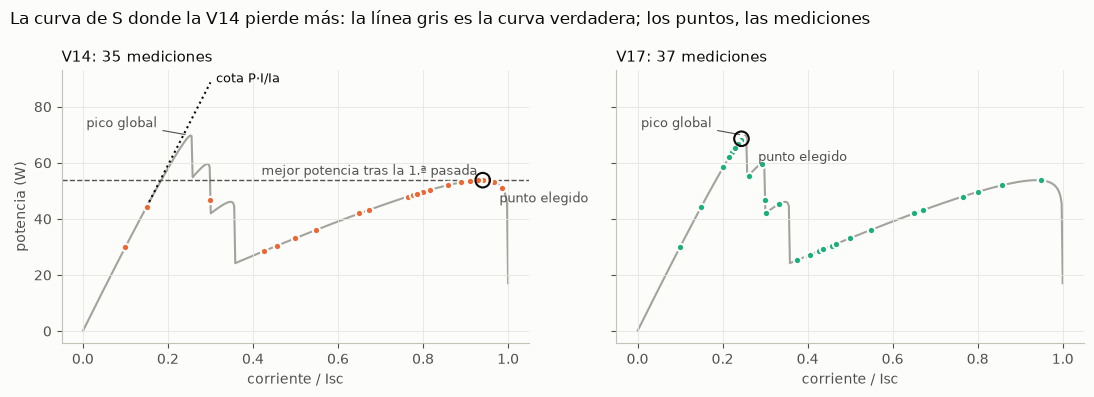

Tras la 1.ª pasada, la cota del intervalo [0.15, 0.30]·Isc es 1.65 veces la mejor potencia: la V17 sondea ahí.


In [3]:
loss14 = base - a; k = int(np.argmax(loss14)); c = S[k]
def correr(fn, curva, semilla):
    rng = np.random.default_rng(semilla); pl = StaticPlant(curva, rng=rng); fn(pl, curva, rng)
    I, P = np.array(pl.log_I), np.array(pl.log_Pmeas); sel = int(np.where(P == P.max())[0][-1]); return I, P, sel
I14, P14, s14 = correr(V14, c, 7 + 1000 * k); I17, P17, s17 = correr(V17, c, 7 + 1000 * k)
print(f"Curva {k}: GMPP {c.P_gmpp:.1f} W en {c.I_gmpp / c.Isc:.2f}·Isc")
print(f"  V14: {len(P14)} mediciones, se queda en {I14[s14] / c.Isc:.2f}·Isc con {P14[s14]:.1f} W  (pierde {loss14[k]:.1f} pp)")
print(f"  V17: {len(P17)} mediciones, se queda en {I17[s17] / c.Isc:.2f}·Isc con {P17[s17]:.1f} W  (pierde {base[k] - final_acc(V17, [c], 0.02)[0][0]:.1f} pp con el retroceso del 2 %; sin retroceso: {base[k] - final_acc(V17, [c])[0][0]:.1f} pp)")

# Intervalo con la cota mayor tras las 7 mediciones de la primera pasada de la V14
iv, Pb = intervals(I14[:7], P14[:7], c.Isc); cota, Ia, Ib = max(iv); Pa = np.interp(Ia, I14[:7][np.argsort(I14[:7])], P14[:7][np.argsort(I14[:7])])

fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (lbl, I, P, s) in zip(axs, [("V14", I14, P14, s14), ("V17", I17, P17, s17)]):
    ax.plot(c.I / c.Isc, c.P, color=COL["curva"], lw=1.5, zorder=1)
    ax.scatter(I / c.Isc, P, s=28, color=COL[lbl], edgecolor="#fcfcfb", linewidth=1.5, zorder=3)
    ax.scatter([I[s] / c.Isc], [P[s]], s=110, facecolor="none", edgecolor=COL["texto"], linewidth=1.5, zorder=4)
    ax.annotate("punto elegido", (I[s] / c.Isc, P[s]), xytext=(12, -16), textcoords="offset points", color=COL["texto2"], fontsize=9)
    ax.annotate("pico global", (c.I_gmpp / c.Isc, c.P_gmpp), xytext=(-75, 6), textcoords="offset points", color=COL["texto2"], fontsize=9,
                arrowprops=dict(arrowstyle="-", color=COL["texto2"], lw=0.8, shrinkA=2, shrinkB=4))
    ax.set_title(f"{lbl}: {len(P)} mediciones", color=COL["texto"], loc="left"); ax.set_xlabel("corriente / Isc")
xs = np.linspace(Ia, Ib, 20)
axs[0].plot(xs / c.Isc, Pa * xs / Ia, ls=":", color=COL["texto"], lw=1.5, zorder=2)
axs[0].axhline(Pb, color=COL["texto2"], lw=1, ls="--", zorder=2)
axs[0].annotate("cota P·I/Ia", (Ib / c.Isc, Pa * Ib / Ia), xytext=(4, 0), textcoords="offset points", color=COL["texto"], fontsize=9)
axs[0].annotate("mejor potencia tras la 1.ª pasada", (0.42, Pb), xytext=(0, 4), textcoords="offset points", color=COL["texto2"], fontsize=9)
axs[0].set_ylabel("potencia (W)")
fig.suptitle("La curva de S donde la V14 pierde más: la línea gris es la curva verdadera; los puntos, las mediciones", x=0.01, ha="left", color=COL["texto"])
plt.tight_layout(); plt.show()
print(f"Tras la 1.ª pasada, la cota del intervalo [{Ia / c.Isc:.2f}, {Ib / c.Isc:.2f}]·Isc es {cota / Pb:.2f} veces la mejor potencia: la V17 sondea ahí.")

## 3. Cola estática, recalculada aquí (curvas S, 1000)

Pérdida de cada método contra el MSAPSO completo, con retroceso del 2 % para V14 y V17 (como en sus reportes).
La gráfica muestra solo el 10 % peor de las curvas, que es donde está la diferencia; la línea vertical marca el p99
y la horizontal, el criterio de 3 pp.

,mediciones,pérdida media (pp),p95 (pp),p99 (pp),peor caso (pp),% curvas > 3 pp
V7,70.00,0.05,0.23,0.64,0.97,0.0
V14,38.76,0.88,1.91,13.01,22.99,3.7
V17,40.10,0.52,1.04,2.33,3.88,0.3


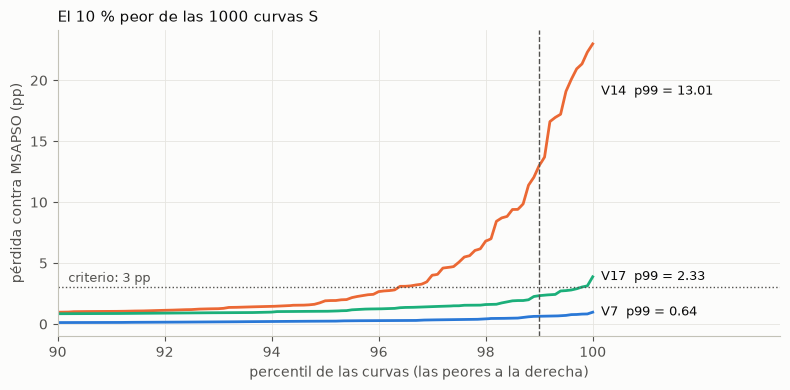

In [4]:
res = {"V7": base - final_acc(V7, S)[0], "V14": loss14, "V17": base - final_acc(V17, S, 0.02)[0]}
med = {"V7": 70, "V14": na.mean(), "V17": final_acc(V17, S, 0.02)[1].mean()}
tabla = pd.DataFrame({m: {"mediciones": med[m], "pérdida media (pp)": d.mean(), "p95 (pp)": np.percentile(d, 95),
                          "p99 (pp)": np.percentile(d, 99), "peor caso (pp)": d.max(), "% curvas > 3 pp": 100 * np.mean(d > 3)}
                      for m, d in res.items()}).T.round(2)
display(tabla)

fig, ax = plt.subplots(figsize=(8, 4))
q = np.linspace(90, 100, 201)
for m, d in res.items():
    y = np.percentile(d, q); ax.plot(q, y, color=COL[m])
    ax.annotate(f"{m}  p99 = {np.percentile(d, 99):.2f}", (100, y[-1] if m != "V14" else np.percentile(d, 99.5)),
                xytext=(6, 0), textcoords="offset points", va="center", color=COL["texto"], fontsize=9)
ax.axvline(99, color=COL["texto2"], lw=1, ls="--"); ax.axhline(3, color=COL["texto2"], lw=1, ls=":")
ax.annotate("criterio: 3 pp", (90.2, 3), xytext=(0, 4), textcoords="offset points", color=COL["texto2"], fontsize=9)
ax.set_xlabel("percentil de las curvas (las peores a la derecha)"); ax.set_ylabel("pérdida contra MSAPSO (pp)")
ax.set_title("El 10 % peor de las 1000 curvas S", loc="left", color=COL["texto"]); ax.set_xlim(90, 103.5); ax.set_xticks(range(90, 101, 2))
plt.tight_layout(); plt.show()

### Todos los conjuntos estáticos de prueba (resultados guardados)

S y P son los de la V14; 9393/9394 y 5252 son conjuntos nuevos que nunca se usaron antes. Criterio: p99 ≤ 3 pp en cada uno.
Para recalcularlos: `python3 estatico_V17.py test "<variante>"` desde la carpeta del código (tarda segundos).

In [5]:
def tabla_estatica(archivo):
    d = json.load(open(archivo)); filas = {}
    for key, v in d.items():
        conj, met = key.split("|")
        etiqueta = {"V7 (parada)": "V7", "V14 (sin verif.) b=0.02": "V14", f"{SEL} b=0.02": "V17"}.get(met)
        if etiqueta: filas.setdefault(conj, {})[f"p99 {etiqueta}"] = v["p99"]
    t = pd.DataFrame(filas).T.round(2); t["V17 cumple (≤ 3 pp)"] = np.where(t["p99 V17"] <= 3, "sí", "NO"); return t
display(tabla_estatica("resultados_V17/estatico_test_V17.json"))

,p99 V7,p99 V14,p99 V17,V17 cumple (≤ 3 pp)
base 1000 (7777/7778),0.64,13.01,2.33,sí
72c-6s 100 (5151),0.55,6.42,1.51,sí
36c-3s 100 (5151),0.45,1.38,1.38,sí
60c-11A 100 (5151),0.26,13.18,1.91,sí
96c-6.5A 100 (5151),0.27,10.43,1.93,sí
base 1000 (9393/9394),0.44,10.91,2.02,sí
72c-6s 100 (5252),0.64,12.56,1.57,sí
36c-3s 100 (5252),0.17,1.12,0.71,sí
60c-11A 100 (5252),0.36,4.57,1.65,sí
96c-6.5A 100 (5252),0.33,4.65,1.70,sí


## 4. Energía dinámica (escenarios de prueba 0–599 y confirmación 1200–2399)

Se leen los resultados guardados por escenario y se recalculan las diferencias con intervalos de confianza al 95 %
(bootstrap pareado, igual que en todos los reportes). Para volver a correr la simulación completa, cambia
`RECALCULAR = True` (tarda 1–2 min con muchos núcleos; ajusta `Pool(22)` en `dinamico_V17.py` si tienes menos).

In [6]:
RECALCULAR = False
if RECALCULAR:
    subprocess.run([sys.executable, "dinamico_V17.py", "test", SEL], check=True)

from entorno_V14 import make_scenario
R = json.load(open("resultados_V17/dinamico_test_V17.json"))
E = {m: np.array([r[k][0] for r in R]) for m, k in [("MSAPSO", "MSAPSO"), ("V7", "V7"), ("V14", "V14"), ("V17", SEL)]}
idx = np.array([r["idx"] for r in R])
def boot(d, B=3000):
    rb = np.random.default_rng(0); m = d[rb.integers(0, len(d), (B, len(d)))].mean(1)
    return d.mean(), np.percentile(m, 2.5), np.percentile(m, 97.5)
fmt = lambda t: f"{t[0]:+.2f} [{t[1]:+.2f}, {t[2]:+.2f}]"
filas = {}
for nombre, m in {"prueba 0–599": idx < 600, "confirmación 1200–2399": idx >= 1200}.items():
    filas[nombre] = {"V14 − V7": fmt(boot((E["V14"] - E["V7"])[m])), "V17 − V7": fmt(boot((E["V17"] - E["V7"])[m])),
                     "V17 − V14": fmt(boot((E["V17"] - E["V14"])[m])),
                     "% pierde > 3 pp vs MSAPSO (V17)": round(100 * np.mean((E["V17"] - E["MSAPSO"])[m] < -3), 1)}
display(pd.DataFrame(filas).T)
print("Criterio 2: V17 − V7 con límite inferior > 0 en ambos, y V17 − V14 ≥ −0.3 pp.")

,V14 − V7,V17 − V7,V17 − V14,% pierde > 3 pp vs MSAPSO (V17)
prueba 0–599,"+1.35 [+0.94, +1.79]","+1.74 [+1.33, +2.17]","+0.38 [+0.03, +0.75]",6.5
confirmación 1200–2399,"+1.60 [+1.24, +1.96]","+1.81 [+1.44, +2.16]","+0.21 [-0.08, +0.47]",6.9


Criterio 2: V17 − V7 con límite inferior > 0 en ambos, y V17 − V14 ≥ −0.3 pp.


### Por tiempo de espera del convertidor (t_wait)

La V14 perdía contra la V7 a 0.5 ms (el t_wait del paper). Aquí se ve si la V17 corrige esa debilidad.
Puntos = diferencia media de energía contra la V7; barras = intervalo de confianza al 95 %.

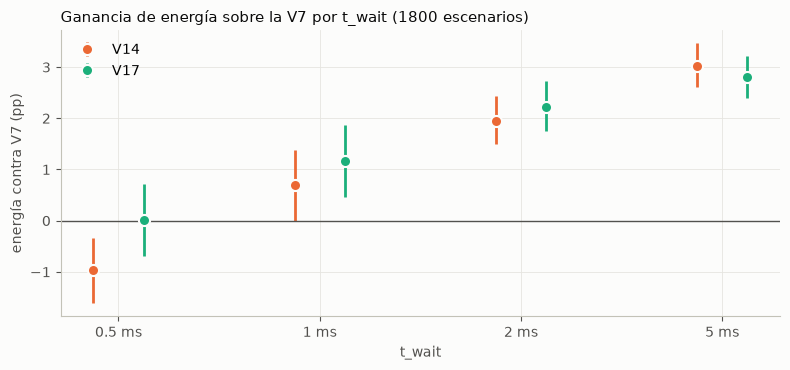

In [7]:
meta = [make_scenario(i)[0] for i in idx]; waits = sorted({x["wait"] for x in meta})
fig, ax = plt.subplots(figsize=(8, 3.8))
for j, m in enumerate(["V14", "V17"]):
    for i, w in enumerate(waits):
        mm = np.array([x["wait"] == w for x in meta]); mu, lo, hi = boot((E[m] - E["V7"])[mm])
        x = i + (j - 0.5) * 0.25
        ax.errorbar(x, mu, yerr=[[mu - lo], [hi - mu]], fmt="o", ms=8, color=COL[m], elinewidth=2, capsize=0,
                    markeredgecolor="#fcfcfb", markeredgewidth=1.5, label=m if i == 0 else None)
ax.axhline(0, color=COL["texto2"], lw=1)
ax.set_xticks(range(len(waits))); ax.set_xticklabels([f"{w * 1e3:g} ms" for w in waits])
ax.set_ylabel("energía contra V7 (pp)"); ax.set_xlabel("t_wait")
ax.set_title("Ganancia de energía sobre la V7 por t_wait (1800 escenarios)", loc="left", color=COL["texto"])
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

## 5. La debilidad que queda: ruido de medición

Sin ruido la V17 cumple en todos los conjuntos. Con ruido de 1 y 2 W en la potencia medida, el p99 estático
vuelve a pasar de 3 pp en algunos paneles (el peor es el de 36 celdas, el de menor potencia, donde 1–2 W pesan más).
Este punto no tenía criterio fijado; se reporta tal cual. Para recalcular: `RUIDO=1 python3 estatico_V17.py test "<variante>"`.

In [8]:
t1 = tabla_estatica("resultados_V17/estatico_test_ruido1_V17.json").add_suffix(" · 1 W")
t2 = tabla_estatica("resultados_V17/estatico_test_ruido2_V17.json").add_suffix(" · 2 W")
display(pd.concat([t1, t2], axis=1)[[c for c in list(t1.columns) + list(t2.columns) if not c.startswith("V17 cumple")]])

,p99 V7 · 1 W,p99 V14 · 1 W,p99 V17 · 1 W,p99 V7 · 2 W,p99 V14 · 2 W,p99 V17 · 2 W
base 1000 (7777/7778),1.44,11.62,3.96,1.76,14.16,5.78
72c-6s 100 (5151),0.89,6.54,1.89,1.96,8.86,5.13
36c-3s 100 (5151),1.79,8.71,9.22,2.49,13.82,8.49
60c-11A 100 (5151),0.99,12.83,2.97,1.20,12.91,3.66
96c-6.5A 100 (5151),1.00,10.07,3.01,2.04,8.64,3.60
base 1000 (9393/9394),0.80,9.93,3.88,1.68,14.20,5.85
72c-6s 100 (5252),0.84,14.37,3.30,1.78,6.54,3.14
36c-3s 100 (5252),1.00,10.27,7.75,1.16,8.89,9.50
60c-11A 100 (5252),0.61,4.47,3.01,0.80,7.52,3.67
96c-6.5A 100 (5252),0.57,4.77,2.87,0.69,5.90,3.72


## 6. Puntos para revisar

- [ ] **Sección 1:** la V17 con la verificación apagada da exactamente lo mismo que la V14.
- [ ] **Sección 2:** en la curva mostrada, la cota apunta al hueco donde está el pico global y la V17 lo encuentra.
- [ ] **Sección 3:** p99 de la V17 ≤ 3 pp en S y en todos los conjuntos de prueba.
- [ ] **Sección 4:** V17 − V7 > 0 con intervalo que no cruza el cero en prueba y confirmación; la debilidad a 0.5 ms ya no está.
- [ ] **Código** (`verificacion_V17.py`): revisar `intervals` (la cota), `sweep_with_probes` (los sondeos intercalados) y `make_intercalado` (la variante final).
- [ ] **Supuestos a discutir:**
    - el método toma la Isc de la curva, como la V7 y la V14 (un controlador real tendría que medirla);
    - en dinámico la cota se calcula con la corriente pedida, así que ahí es una regla práctica, no una garantía física;
    - los escenarios de validación se usaron en tres rondas de diseño.
- [ ] **Sección 5:** decidir si la sensibilidad al ruido bloquea proponer la V17 o queda como siguiente paso.

Documentos: `README_V17.md` (veredicto) y `diseno_V17.md` (criterios y revisiones), en `MSAPSO Claude/Modelo Final/Frente_B_cola_V17/`.